# MSCS 634 — Lab 1: Data Visualization, Preprocessing, and Statistical Analysis

**Name:** Sandeep Reddy Polareddy 
**Course:** MSCS 634  
**Lab Assignment:** Lab 1 — Data Visualization, Preprocessing, and Statistical Analysis

## Purpose
This notebook explores a retail sales dataset using Pandas, Matplotlib, and scikit-learn. It includes visualization, missing-value treatment, IQR-based outlier handling, data reduction, scaling, discretization, descriptive statistics, and correlation analysis.

**Dataset:** `retail_sales.csv` (included in the same repository). The dataset contains 120 retail transactions. A small number of missing values and intentionally unusual numeric values are included so preprocessing steps can be demonstrated.


## Step 1: Data Collection

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from pathlib import Path

# If this notebook and retail_sales.csv are in the same folder, this path works.
df = pd.read_csv("retail_sales.csv", parse_dates=["Order_Date"])
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (120, 8)


,Order_Date,Region,Product,Units_Sold,Unit_Price,Discount,Sales,Customer_Satisfaction
0,2025-01-01,South,Headphones,5,90.0,0.05,441.11,3.6
1,2025-01-02,West,Keyboard,7,55.0,0.00,380.80,4.4
2,2025-01-03,West,Laptop,13,850.0,0.05,10519.32,3.5
3,2025-01-04,East,Monitor,7,240.0,0.10,1510.74,4.7
4,2025-01-05,East,Laptop,5,850.0,0.20,3395.18,1.9


**Interpretation:** The first five rows show the dataset's structure: order date, region, product, units sold, unit price, discount, sales revenue, and customer satisfaction. `head()` is the required preview for the data-collection screenshot.

## Step 2: Data Visualization

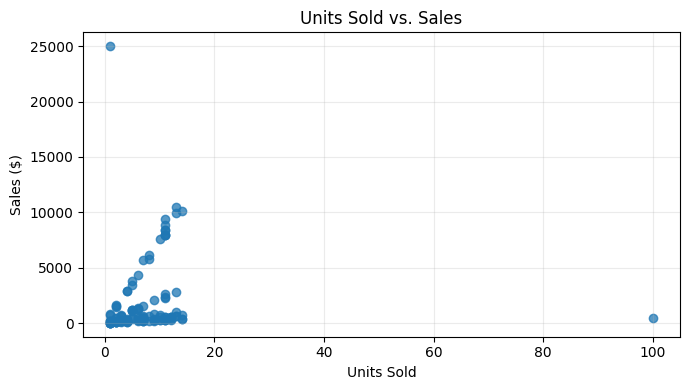

In [3]:
# Scatter plot: units sold versus sales
plt.figure(figsize=(7, 4))
plt.scatter(df["Units_Sold"], df["Sales"], alpha=0.75)
plt.title("Units Sold vs. Sales")
plt.xlabel("Units Sold")
plt.ylabel("Sales ($)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


**Insight — scatter plot:** Sales generally increase as units sold increase, although product prices and discounts also affect revenue. The unusually high unit count and sales value may appear as outliers and should be checked before drawing conclusions.

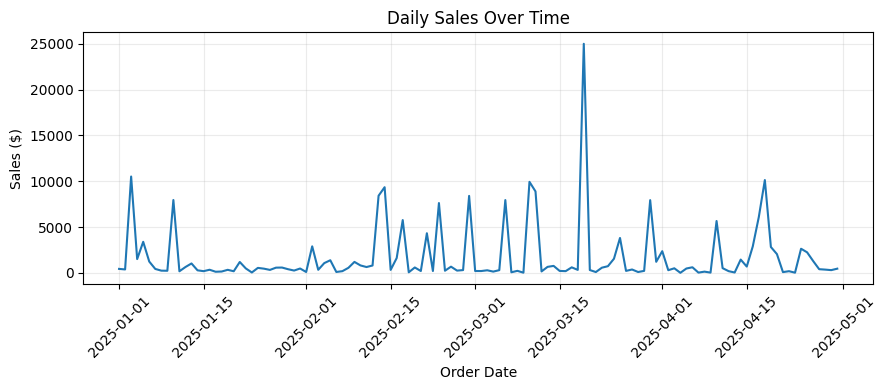

In [4]:
# Line plot: daily sales
daily_sales = df.groupby("Order_Date", as_index=False)["Sales"].sum()
plt.figure(figsize=(9, 4))
plt.plot(daily_sales["Order_Date"], daily_sales["Sales"], linewidth=1.5)
plt.title("Daily Sales Over Time")
plt.xlabel("Order Date")
plt.ylabel("Sales ($)")
plt.xticks(rotation=45)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


**Insight — line plot:** Daily revenue fluctuates because each day contains a different product mix, quantity, and discount. Since the dataset covers only a short period and has one transaction per date, the line is useful for showing variation but not enough to establish a long-term seasonal pattern.

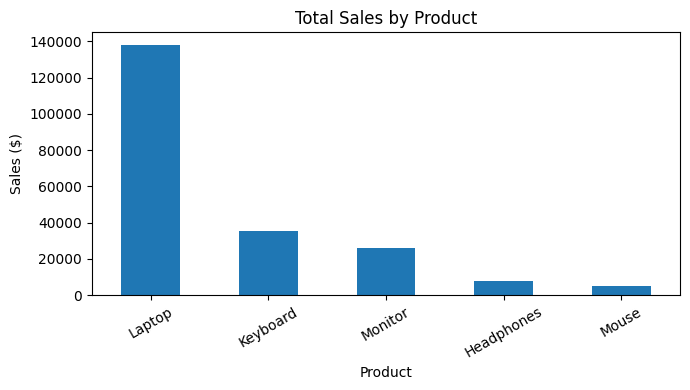

In [5]:
# Bar chart: total sales by product
product_sales = df.groupby("Product")["Sales"].sum().sort_values(ascending=False)
product_sales.plot(kind="bar", figsize=(7, 4), title="Total Sales by Product", ylabel="Sales ($)", xlabel="Product")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Insight — bar chart:** This chart compares total revenue across product categories. Product totals reflect both price and quantity sold, so the highest-revenue category is not necessarily the category with the most units sold.

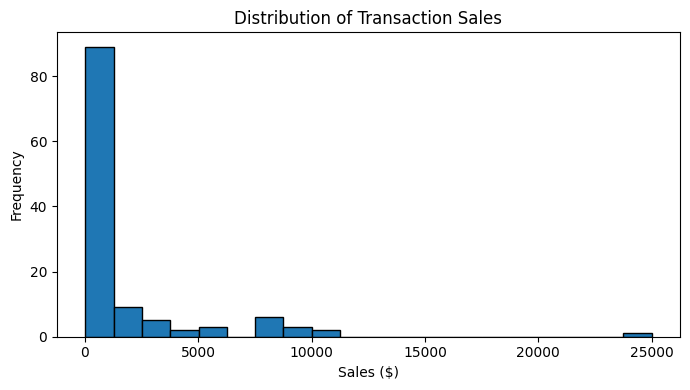

In [6]:
# Histogram: sales distribution
plt.figure(figsize=(7, 4))
plt.hist(df["Sales"].dropna(), bins=20, edgecolor="black")
plt.title("Distribution of Transaction Sales")
plt.xlabel("Sales ($)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


**Insight — histogram:** The sales distribution is expected to be right-skewed because products have different price points and an unusually large sales value is present. This is a reason to inspect outliers and compare the distribution before and after handling them.

## Step 3: Data Preprocessing

### 3.1 Detect and handle missing values

In [7]:
print("Missing values before treatment:")
display(df.isna().sum().to_frame("Missing_Count"))
print("Preview before treatment:")
display(df[df.isna().any(axis=1)].head(10))

clean = df.copy()
# Fill categorical values with their mode; numeric values with their median.
for col in ["Region", "Product"]:
    clean[col] = clean[col].fillna(clean[col].mode().iloc[0])
for col in ["Discount", "Customer_Satisfaction"]:
    clean[col] = clean[col].fillna(clean[col].median())

print("Missing values after treatment:")
display(clean.isna().sum().to_frame("Missing_Count"))
display(clean.head())


Missing values before treatment:


,Missing_Count
Order_Date,0
Region,2
Product,0
Units_Sold,0
Unit_Price,0
Discount,2
Sales,0
Customer_Satisfaction,2


Preview before treatment:


,Order_Date,Region,Product,Units_Sold,Unit_Price,Discount,Sales,Customer_Satisfaction
7,2025-01-08,NaN,Headphones,3,90.0,0.1,248.90,2.7
12,2025-01-13,South,Headphones,13,90.0,NaN,1033.75,4.8
19,2025-01-20,South,Mouse,7,28.0,0.1,184.03,NaN
41,2025-02-11,NaN,Keyboard,13,55.0,0.1,643.88,3.9
68,2025-03-10,South,Laptop,13,850.0,NaN,9938.80,3.7
92,2025-04-03,North,Headphones,7,90.0,0.2,505.68,NaN


Missing values after treatment:


,Missing_Count
Order_Date,0
Region,0
Product,0
Units_Sold,0
Unit_Price,0
Discount,0
Sales,0
Customer_Satisfaction,0


,Order_Date,Region,Product,Units_Sold,Unit_Price,Discount,Sales,Customer_Satisfaction
0,2025-01-01,South,Headphones,5,90.0,0.05,441.11,3.6
1,2025-01-02,West,Keyboard,7,55.0,0.00,380.80,4.4
2,2025-01-03,West,Laptop,13,850.0,0.05,10519.32,3.5
3,2025-01-04,East,Monitor,7,240.0,0.10,1510.74,4.7
4,2025-01-05,East,Laptop,5,850.0,0.20,3395.18,1.9


**Decision and insight:** Missing categorical values are replaced with the most frequent category (mode), while missing numeric values are replaced with the median. The median is less affected by extreme values than the mean. Dates and the remaining columns are complete in this sample, so no rows need to be dropped.

### 3.2 Detect and handle outliers with the IQR method

In [8]:
numeric_for_iqr = ["Units_Sold", "Unit_Price", "Sales", "Customer_Satisfaction"]
iqr_rows = []
outlier_mask = pd.Series(False, index=clean.index)

for col in numeric_for_iqr:
    q1 = clean[col].quantile(0.25)
    q3 = clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (clean[col] < lower) | (clean[col] > upper)
    outlier_mask |= mask
    iqr_rows.append({
        "Column": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "Lower_Bound": lower, "Upper_Bound": upper,
        "Outlier_Count": int(mask.sum())
    })

iqr_summary = pd.DataFrame(iqr_rows)
display(iqr_summary.round(2))
print("Rows flagged as outliers (before handling):", int(outlier_mask.sum()))
display(clean.loc[outlier_mask, ["Order_Date", "Product"] + numeric_for_iqr])

# Remove rows flagged as outliers in any of the selected numeric columns.
# This is a demonstration choice; in real projects, verify unusual values first.
no_outliers = clean.loc[~outlier_mask].copy()
print("Shape before outlier handling:", clean.shape)
print("Shape after outlier handling:", no_outliers.shape)
display(no_outliers.head())


,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count
0,Units_Sold,3.00,11.00,8.00,-9.00,23.00,1
1,Unit_Price,55.00,240.00,185.00,-222.50,517.50,24
2,Sales,216.75,1323.27,1106.52,-1443.03,2983.04,18
3,Customer_Satisfaction,3.50,4.60,1.10,1.85,6.25,1


Rows flagged as outliers (before handling): 26


,Order_Date,Product,Units_Sold,Unit_Price,Sales,Customer_Satisfaction
2,2025-01-03,Laptop,13,850.0,10519.32,3.5
4,2025-01-05,Laptop,5,850.0,3395.18,1.9
9,2025-01-10,Laptop,11,850.0,7955.65,4.6
30,2025-01-31,Keyboard,100,55.0,482.60,3.8
32,2025-02-02,Laptop,4,850.0,2901.56,4.9
42,2025-02-12,Laptop,1,850.0,811.34,5.0
43,2025-02-13,Laptop,11,850.0,8421.80,4.7
44,2025-02-14,Laptop,11,850.0,9353.49,5.0
46,2025-02-16,Laptop,2,850.0,1624.26,5.0
47,2025-02-17,Laptop,8,850.0,5765.87,4.1


Shape before outlier handling: (120, 8)
Shape after outlier handling: (94, 8)


,Order_Date,Region,Product,Units_Sold,Unit_Price,Discount,Sales,Customer_Satisfaction
0,2025-01-01,South,Headphones,5,90.0,0.05,441.11,3.6
1,2025-01-02,West,Keyboard,7,55.0,0.00,380.80,4.4
3,2025-01-04,East,Monitor,7,240.0,0.10,1510.74,4.7
5,2025-01-06,North,Monitor,6,240.0,0.15,1241.86,4.3
6,2025-01-07,East,Monitor,2,240.0,0.10,436.17,2.4


**Decision and insight:** The IQR rule flags values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. Rows flagged in any selected numeric field are removed in this demonstration. In real analysis, investigate whether an extreme value is an error or a genuine transaction before removing it.

### 3.3 Data reduction: sampling and dropping a less relevant column

In [9]:
# Use the cleaned, outlier-filtered data as the starting point for reduction.
reduced_source = no_outliers.copy()
print("Before reduction:", reduced_source.shape)
display(reduced_source.head())

# Keep a reproducible 60% sample and drop Unit_Price for a compact analysis view.
reduced = reduced_source.sample(frac=0.60, random_state=42).drop(columns=["Unit_Price"])
print("After 60% sampling and dropping Unit_Price:", reduced.shape)
display(reduced.head())


Before reduction: (94, 8)


,Order_Date,Region,Product,Units_Sold,Unit_Price,Discount,Sales,Customer_Satisfaction
0,2025-01-01,South,Headphones,5,90.0,0.05,441.11,3.6
1,2025-01-02,West,Keyboard,7,55.0,0.00,380.80,4.4
3,2025-01-04,East,Monitor,7,240.0,0.10,1510.74,4.7
5,2025-01-06,North,Monitor,6,240.0,0.15,1241.86,4.3
6,2025-01-07,East,Monitor,2,240.0,0.10,436.17,2.4


After 60% sampling and dropping Unit_Price: (56, 7)


,Order_Date,Region,Product,Units_Sold,Discount,Sales,Customer_Satisfaction
50,2025-02-20,South,Headphones,3,0.20,209.79,4.4
25,2025-01-26,East,Mouse,11,0.00,330.73,3.7
72,2025-03-14,South,Headphones,10,0.15,768.68,5.0
93,2025-04-04,East,Mouse,1,0.15,14.33,4.2
0,2025-01-01,South,Headphones,5,0.05,441.11,3.6


**Decision and insight:** A reproducible 60% sample reduces the number of rows while retaining a useful subset for demonstration. `Unit_Price` is dropped from this reduced view because sales already reflects price, quantity, and discount; it remains available in the original cleaned dataset. Sampling can omit rare patterns, so use the full dataset for final business decisions.

### 3.4 Scaling and discretization

In [10]:
# Min-Max scale Units_Sold to a 0–1 range on the reduced dataset.
scaled = reduced.copy()
scaler = MinMaxScaler()
scaled["Units_Sold_MinMax"] = scaler.fit_transform(scaled[["Units_Sold"]])

# Discretize Sales into three interpretable categories based on this sample's distribution.
scaled["Sales_Band"] = pd.qcut(
    scaled["Sales"], q=3, labels=["Low", "Medium", "High"], duplicates="drop"
)
display(reduced[["Units_Sold", "Sales"]].head())
display(scaled[["Units_Sold", "Units_Sold_MinMax", "Sales", "Sales_Band"]].head())
print("Scaled units range:",
      round(scaled["Units_Sold_MinMax"].min(), 3),
      "to", round(scaled["Units_Sold_MinMax"].max(), 3))


,Units_Sold,Sales
50,3,209.79
25,11,330.73
72,10,768.68
93,1,14.33
0,5,441.11


,Units_Sold,Units_Sold_MinMax,Sales,Sales_Band
50,3,0.153846,209.79,Low
25,11,0.769231,330.73,Medium
72,10,0.692308,768.68,High
93,1,0.000000,14.33,Low
0,5,0.307692,441.11,Medium


Scaled units range: 0.0 to 1.0


**Insight:** Min-Max scaling transforms `Units_Sold` to a 0–1 range while preserving relative ordering. Sales discretization creates Low, Medium, and High categories based on sample quantiles. These bins are relative to this dataset rather than universal business thresholds.

## Step 4: Statistical Analysis

### 4.1 General overview: `.info()` and `.describe()`

In [11]:
print("Dataset information:")
clean.info()
print("\nDescriptive statistics:")
display(clean.describe(include="all").T)


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Order_Date             120 non-null    datetime64[ns]
 1   Region                 120 non-null    object        
 2   Product                120 non-null    object        
 3   Units_Sold             120 non-null    int64         
 4   Unit_Price             120 non-null    float64       
 5   Discount               120 non-null    float64       
 6   Sales                  120 non-null    float64       
 7   Customer_Satisfaction  120 non-null    float64       
dtypes: datetime64[ns](1), float64(4), int64(1), object(2)
memory usage: 7.6+ KB

Descriptive statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Order_Date,120,NaN,NaN,NaN,2025-03-01 12:00:00,2025-01-01 00:00:00,2025-01-30 18:00:00,2025-03-01 12:00:00,2025-03-31 06:00:00,2025-04-30 00:00:00,NaN
Region,120,4,East,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,120,5,Keyboard,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Units_Sold,120.0,NaN,NaN,NaN,7.416667,1.0,3.0,6.0,11.0,100.0,9.402828
Unit_Price,120.0,NaN,NaN,NaN,246.0,28.0,55.0,90.0,240.0,850.0,311.541033
Discount,120.0,NaN,NaN,NaN,0.087917,0.0,0.05,0.1,0.15,0.2,0.062172
Sales,120.0,NaN,NaN,NaN,1769.482667,14.33,216.75,465.565,1323.2675,25000.0,3362.018339
Customer_Satisfaction,120.0,NaN,NaN,NaN,3.9825,1.7,3.5,3.95,4.6,5.0,0.724646


**Interpretation:** `.info()` reports the row count, non-null counts, and data types. `.describe()` summarizes numeric columns using count, mean, standard deviation, minimum, quartiles, and maximum. Compare the maximum values with the quartiles to identify possible extreme observations.

### 4.2 Central tendency and minimum/maximum

In [12]:
numeric_cols = clean.select_dtypes(include="number").columns
central_tendency = pd.DataFrame({
    "Minimum": clean[numeric_cols].min(),
    "Maximum": clean[numeric_cols].max(),
    "Mean": clean[numeric_cols].mean(),
    "Median": clean[numeric_cols].median(),
    "Mode": clean[numeric_cols].mode().iloc[0]
})
display(central_tendency.round(2))


,Minimum,Maximum,Mean,Median,Mode
Units_Sold,1.00,100.0,7.42,6.00,11.00
Unit_Price,28.00,850.0,246.00,90.00,55.00
Discount,0.00,0.2,0.09,0.10,0.10
Sales,14.33,25000.0,1769.48,465.56,14.33
Customer_Satisfaction,1.70,5.0,3.98,3.95,5.00


**Interpretation:** The mean uses every value and can be pulled upward by extreme observations; the median is the middle value and is more robust to skew. The mode is the most frequently occurring value (the first mode is displayed if there is a tie).

### 4.3 Dispersion measures

In [13]:
dispersion = pd.DataFrame(index=numeric_cols)
dispersion["Range"] = clean[numeric_cols].max() - clean[numeric_cols].min()
dispersion["Q1"] = clean[numeric_cols].quantile(0.25)
dispersion["Q2_Median"] = clean[numeric_cols].quantile(0.50)
dispersion["Q3"] = clean[numeric_cols].quantile(0.75)
dispersion["IQR"] = dispersion["Q3"] - dispersion["Q1"]
dispersion["Variance"] = clean[numeric_cols].var()
dispersion["Std_Dev"] = clean[numeric_cols].std()
display(dispersion.round(2))


,Range,Q1,Q2_Median,Q3,IQR,Variance,Std_Dev
Units_Sold,99.00,3.00,6.00,11.00,8.00,88.41,9.40
Unit_Price,822.00,55.00,90.00,240.00,185.00,97057.82,311.54
Discount,0.20,0.05,0.10,0.15,0.10,0.00,0.06
Sales,24985.67,216.75,465.56,1323.27,1106.52,11303167.31,3362.02
Customer_Satisfaction,3.30,3.50,3.95,4.60,1.10,0.53,0.72


**Interpretation:** Range describes the full spread from minimum to maximum. Quartiles and IQR describe the middle 50% of observations. Variance and standard deviation summarize spread around the mean, with standard deviation expressed in the original variable's units. Large ranges or standard deviations may reflect differences between product categories or outliers.

### 4.4 Correlation analysis

,Units_Sold,Unit_Price,Discount,Sales,Customer_Satisfaction
Units_Sold,1.000,-0.016,-0.073,0.069,-0.024
Unit_Price,-0.016,1.000,0.199,0.595,-0.048
Discount,-0.073,0.199,1.000,0.138,-0.086
Sales,0.069,0.595,0.138,1.000,-0.144
Customer_Satisfaction,-0.024,-0.048,-0.086,-0.144,1.000


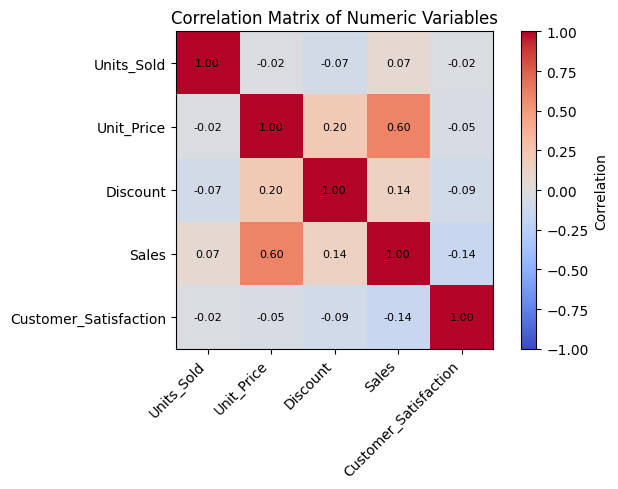

In [14]:
correlation = clean.select_dtypes(include="number").corr()
display(correlation.round(3))

plt.figure(figsize=(7, 5))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation.index)), correlation.index)
for i in range(len(correlation.index)):
    for j in range(len(correlation.columns)):
        plt.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Correlation Matrix of Numeric Variables")
plt.tight_layout()
plt.show()


**Interpretation:** Correlation values range from −1 to +1. Positive values indicate that two variables tend to increase together; negative values indicate an inverse relationship; values near zero indicate a weak linear relationship. Correlation does not prove causation. In this dataset, `Sales` is mechanically related to units sold, unit price, and discount, so interpret those relationships in the context of how sales was calculated.

## Conclusion

This lab used visualization to inspect relationships and distributions, preprocessing to address missing values and outliers, data reduction to create a smaller working sample, and descriptive statistics and correlation to summarize the data. The key practical lesson is to inspect data quality before interpreting results: extreme values and missing entries can influence averages, charts, and correlations. The notebook uses a synthetic retail dataset so the steps are reproducible; replace it with a real dataset if your instructor requires one.